# Parte IV. Análisis de enlaces: PageRank y HITS

**Integrantes:** Ricardo Acuña, Juan Aquino y Camilo Soto.

**Pregunta que responde.** ¿Quién es central en el mercado de compras públicas, y qué significa serlo? Contar adjudicaciones o sumar montos ya lo hizo el proyecto 1. El análisis de enlaces responde algo distinto: un proveedor es central si le gana a proveedores que a su vez ganan (PageRank), y una entidad o un proveedor son centrales si se refuerzan mutuamente, entidades que contratan a proveedores de referencia y proveedores contratados por entidades que marcan el mercado (HITS).

**La lección de la propuesta, puesta a prueba.** PageRank depende por completo de qué significa una arista. Sobre el grafo de coparticipación de la Parte I, que es no dirigido, PageRank casi coincide con el grado y no aporta. Por eso esta parte construye un grafo dirigido nuevo, del perdedor al ganador de cada proceso, y reserva el bipartito entidad a proveedor para HITS.

**Dónde corre.** La construcción del grafo dirigido y un PageRank completo corren en Spark, con una iteración de potencia sobre DataFrames que replica lo que hace GraphFrames. El barrido del factor de amortiguamiento, HITS y la verificación corren en local con scipy, porque el grafo cabe en memoria y cada corrida cuesta milisegundos. La sección 3 mide ambas cosas.

In [1]:
import sys, time
from pathlib import Path

# Los ayudantes del proyecto viven en notebooks/scripts. Se importan por
# nombre, no con asterisco, para que quede claro de donde sale cada uno.
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "notebooks" / "scripts"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import functions as F
from scipy import sparse, stats
from scipy.sparse.linalg import svds

from helpers import (BASE, FIGS, ARTEFACTOS, FIGURAS, HALLAZGOS, PALETA,
                     AZUL, ROJO, VERDE, MORADO, TEAL, TINTA, SUAVE, REJILLA, fmt, MILES,
                     abrir_spark, cronometro, figura, exportar, hallazgo, barras_h)
from enlaces import (matriz_transicion, pagerank_local, pagerank_spark, hits_local,
                     solapamiento_top, verificar)
import ingesta

pd.set_option("display.width", 190)
pd.set_option("display.max_colwidth", 64)

# Los pasos caros (el grafo dirigido y el PageRank de Spark) se guardan en
# data/processed y se reutilizan si ya existen. Poner True para recalcularlos.
RECALCULAR = False
CACHE = BASE / "parte4"
CACHE.mkdir(exist_ok=True)

spark = abrir_spark("P2-IV-Enlaces", memoria="2g")
part = spark.read.parquet(str(BASE / "participaciones")).select("ocid", "nodo").dropDuplicates()
hechos = spark.read.parquet(str(BASE / "hechos"))
nodos_g1 = spark.read.parquet(str(BASE / "grafo_nodos")).toPandas()
mapa = (spark.read.parquet(str(BASE / "mapa_proveedores")).select("nodo", "nombre", "tipo")
        .dropDuplicates(["nodo"]).toPandas())
entidades = spark.read.parquet(str(BASE / "caracteristicas_entidades")).toPandas()
clusters = spark.read.parquet(str(BASE / "clusters_proveedores")).toPandas()
perfiles = pd.read_csv(ARTEFACTOS / "p2_perfiles.csv")[["cluster", "perfil"]]
print("pruebas a mano de PageRank y HITS:", verificar())

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/16 20:36:08 WARN Utils: Your hostname, germain-ThinkPad-E15-Gen-2, resolves to a loopback address: 127.0.1.1; using 192.168.1.27 instead (on interface wlp0s20f3)
26/11/16 20:36:08 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/16 20:36:09 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


pruebas a mano de PageRank y HITS: True


## 1. Por qué el grafo de coparticipación no basta

En un grafo no dirigido, una caminata aleatoria sin teletransporte visita cada nodo en proporción a su grado ponderado: es un resultado clásico de cadenas de Markov. Con teletransporte la igualdad deja de ser exacta, pero el orden casi no cambia. Si eso se cumple aquí, PageRank sobre el grafo de coparticipación diría lo mismo que contar con cuántos proveedores compite cada uno, y no justificaría el cálculo.

Se mide directamente: PageRank con beta igual a 0,85 sobre las aristas de la Parte I, en las dos direcciones, contra la fuerza de cada nodo, que es la suma de los pesos de sus aristas.

G1: 70,383 nodos, 2,498,491 aristas, PageRank en 103 iteraciones
Spearman entre PageRank y fuerza: 0.919; top 100 compartido: 88 %



Lectura de f19_g1_pagerank_vs_fuerza
Sobre el grafo de coparticipación, el orden de PageRank y el de la fuerza coinciden en lo esencial: correlación de rangos de 0.919 y 88 de los 100 primeros en común. La nube es una recta en escala logarítmica. PageRank no está mal calculado, es que en un grafo no dirigido una caminata aleatoria pasa por cada nodo en proporción a su grado. Para que el rango diga algo que no diga el conteo, la arista tiene que tener dirección y la dirección tiene que significar algo.



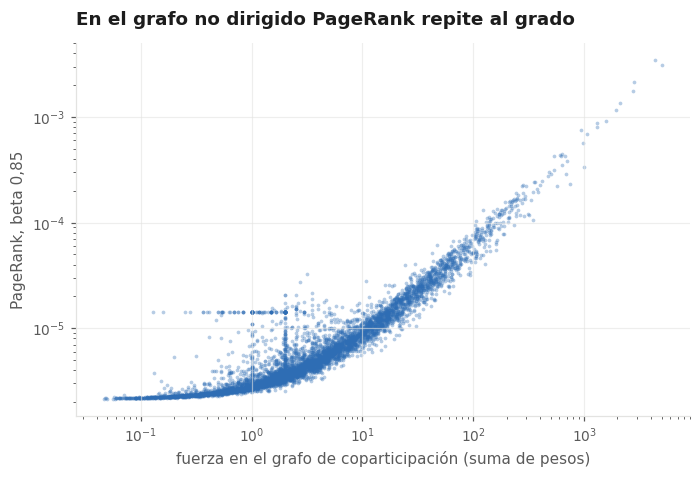

In [2]:
g1 = spark.read.parquet(str(BASE / "grafo_aristas")).select("src", "dst", "peso").toPandas()
idx1 = pd.Index(np.union1d(g1.src.values, g1.dst.values))
s1, d1 = idx1.get_indexer(g1.src), idx1.get_indexer(g1.dst)
M1, sin1 = matriz_transicion(np.r_[s1, d1], np.r_[d1, s1], np.r_[g1.peso, g1.peso], len(idx1))
r1, it1 = pagerank_local(M1, sin1, beta=0.85)
fuerza1 = np.bincount(np.r_[s1, d1], weights=np.r_[g1.peso, g1.peso], minlength=len(idx1))
rho1 = stats.spearmanr(r1, fuerza1).statistic
top1 = solapamiento_top(r1, fuerza1, 100)
print(f"G1: {len(idx1):,} nodos, {len(g1):,} aristas, PageRank en {it1} iteraciones")
print(f"Spearman entre PageRank y fuerza: {rho1:.3f}; top 100 compartido: {100*top1:.0f} %")

fig, ax = plt.subplots(figsize=(7.2, 4.4))
m = np.random.default_rng(0).choice(len(idx1), 6000, replace=False)
ax.scatter(fuerza1[m], r1[m], s=6, alpha=.35, color=AZUL, linewidths=0)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("fuerza en el grafo de coparticipación (suma de pesos)")
ax.set_ylabel("PageRank, beta 0,85")
ax.set_title("En el grafo no dirigido PageRank repite al grado", loc="left", pad=12)
ax.grid(alpha=.6)
figura(fig, "f19_g1_pagerank_vs_fuerza", f"""
Sobre el grafo de coparticipación, el orden de PageRank y el de la fuerza coinciden en lo esencial:
correlación de rangos de {rho1:.3f} y {100*top1:.0f} de los 100 primeros en común. La nube es una recta
en escala logarítmica. PageRank no está mal calculado, es que en un grafo no dirigido una caminata
aleatoria pasa por cada nodo en proporción a su grado. Para que el rango diga algo que no diga el
conteo, la arista tiene que tener dirección y la dirección tiene que significar algo.""")

## 2. El grafo dirigido de perdedor a ganador

**Definición.** En cada proceso con ganador, cada participante que no ganó apunta a cada ganador. La arista se lee como un voto: perder contra alguien es reconocer que, en ese proceso, fue mejor opción para la entidad. PageRank sobre este grafo premia al que le gana a quienes ganan, porque el rango que recibe un perdedor de sus propias victorias se transmite al que lo derrotó.

**Decisiones, cada una con su motivo.**

1. **Los mismos procesos que el grafo de la Parte I**, de 2 a 50 participantes. En un proceso de 300 participantes la mayoría se registra y no compite; sus votos dominarían el grafo.
2. **Peso 1 / w** por perdedor y proceso, con w el número de ganadores. Un proceso por ítems con tres ganadores reparte el voto en lugar de triplicarlo.
3. **Los procesos sin ganador no generan aristas.** Un proceso desierto no dice quién fue mejor.
4. **Los que nunca pierden son dead ends** y su rango se reparte uniforme, como en la matriz M' de la lecture. Los que nunca ganan no reciben aristas y se quedan con el rango mínimo del teletransporte.

La construcción corre en Spark: es un autojoin de 2,2 millones de participaciones contra los ganadores de cada proceso.

In [3]:
n_part = part.groupBy("ocid").agg(F.count("*").alias("n"))
validos = n_part.filter("n BETWEEN 2 AND 50").select("ocid")
gan = hechos.select("ocid", "nodo").dropna().dropDuplicates().join(validos, "ocid")
w = gan.groupBy("ocid").agg(F.count("*").alias("w"))
perdedores = (part.join(validos, "ocid")
              .join(gan.withColumn("gano", F.lit(1)), ["ocid", "nodo"], "left")
              .filter(F.col("gano").isNull()).select("ocid", F.col("nodo").alias("src")))
if RECALCULAR or not (BASE / "grafo_ganadores" / "_SUCCESS").exists():
    with cronometro("construcción del grafo de perdedor a ganador en Spark"):
        g3 = (perdedores.join(gan.withColumnRenamed("nodo", "dst"), "ocid").join(w, "ocid")
              .groupBy("src", "dst")
              .agg(F.sum(1.0 / F.col("w")).alias("peso"), F.count("*").alias("procesos")))
        g3.write.mode("overwrite").parquet(str(BASE / "grafo_ganadores"))
g3 = spark.read.parquet(str(BASE / "grafo_ganadores"))
# Victorias en procesos disputados: procesos que el nodo ganó y en los que hubo al menos un perdedor.
disputados = perdedores.select("ocid").distinct()
ganadas = (gan.join(disputados, "ocid").groupBy("nodo").agg(F.count("*").alias("victorias_disputadas"))
           .toPandas())
nodos3 = g3.select(F.col("src").alias("nodo")).union(g3.select(F.col("dst").alias("nodo"))).distinct()

G3 = g3.toPandas()
idx3 = pd.Index(np.union1d(G3.src.values, G3.dst.values))
s3, d3 = idx3.get_indexer(G3.src), idx3.get_indexer(G3.dst)
M3, sin3 = matriz_transicion(s3, d3, G3.peso.values, len(idx3))
nunca_ganan = len(idx3) - len(np.unique(d3))
estructura = pd.DataFrame([
    {"medida": "procesos con 2 a 50 participantes", "valor": validos.count()},
    {"medida": "procesos con ganador entre ellos", "valor": gan.select("ocid").distinct().count()},
    {"medida": "nodos", "valor": len(idx3)},
    {"medida": "aristas", "valor": len(G3)},
    {"medida": "dead ends: ganan y nunca pierden", "valor": int(sin3.sum())},
    {"medida": "nunca ganan: solo emiten votos", "valor": nunca_ganan},
    {"medida": "aristas recíprocas: A le ganó a B y B a A", "valor": int(len(G3.merge(
        G3[["src", "dst"]].rename(columns={"src": "dst", "dst": "src"}), on=["src", "dst"])) // 2)}])
exportar(estructura, "p4_estructura_g3", "Tamano y forma del grafo dirigido de perdedor a ganador")

,medida,valor
0,procesos con 2 a 50 participantes,142624
1,procesos con ganador entre ellos,119841
2,nodos,134885
3,aristas,1173510
4,dead ends: ganan y nunca pierden,24929
5,nunca ganan: solo emiten votos,83195
6,aristas recíprocas: A le ganó a B y B a A,45429


## 3. PageRank en Spark y verificación en local

La iteración es la de la lecture: r = beta M r + (1 menos beta) / N, con la masa de los dead ends repartida en forma uniforme. En Spark cada paso es un join de las aristas con el rango vigente, una suma por destino y un localCheckpoint que corta el linaje; sin el checkpoint, la iteración 50 volvería a calcular las 49 anteriores. Es lo mismo que hace el PageRank de GraphFrames con su modelo de mensajes, sin agregar un paquete externo cuya versión para Spark 4 no está publicada.

La versión local con scipy sirve de referencia: si las dos implementaciones coinciden al octavo decimal, ninguna tiene un error de normalización.

   implementacion  iteraciones  segundos  diferencia_maxima  top100_igual_pct
Spark, DataFrames           79     54.40       3.478060e-10             100.0
     local, scipy          108      0.25       3.478060e-10             100.0



Lectura de f20_convergencia_pagerank
El cambio entre iteraciones cae de forma geométrica y siempre por debajo de la cota beta elevado a t, que es la garantía teórica: con beta igual a 0.85, cada paso reduce el error al menos en un 15 por ciento. Spark necesitó 79 iteraciones y 54 segundos; scipy, 108 iteraciones y 0.25 segundos con una tolerancia más estricta. Las dos coinciden hasta 3e-10 en el peor nodo y en el 100 por ciento del top 100. A este tamaño, con 134,885 nodos, la iteración local es mucho más rápida; Spark se justifica cuando el grafo deja de caber en una máquina, y el código ya está escrito para ese caso.



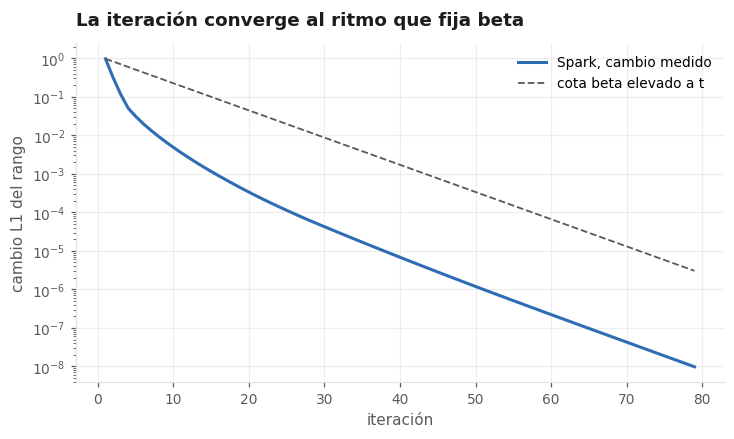

In [4]:
BETA = 0.85
if RECALCULAR or not (CACHE / "pagerank_spark.parquet").exists():
    t0 = time.perf_counter()
    pr_spark, historial = pagerank_spark(spark, g3, nodos3, beta=BETA, tol=1e-8, max_iter=100)
    pr_spark = pr_spark.toPandas()
    t_spark = time.perf_counter() - t0
    pr_spark.to_parquet(CACHE / "pagerank_spark.parquet")
    pd.DataFrame(historial).assign(total=t_spark).to_parquet(CACHE / "historial_spark.parquet")
pr_spark = pd.read_parquet(CACHE / "pagerank_spark.parquet")
_h = pd.read_parquet(CACHE / "historial_spark.parquet")
historial, t_spark = _h.drop(columns="total").to_dict("records"), float(_h.total.iloc[0])
t0 = time.perf_counter()
pr3, it3 = pagerank_local(M3, sin3, beta=BETA, tol=1e-10)
t_local = time.perf_counter() - t0
ref = pd.Series(pr3, index=idx3)
dif = np.abs(pr_spark.set_index("nodo").pagerank.reindex(idx3).values - pr3).max()
top_igual = solapamiento_top(pr_spark.set_index("nodo").pagerank.reindex(idx3).values, pr3, 100)
comparacion = pd.DataFrame([
    {"implementacion": "Spark, DataFrames", "iteraciones": len(historial), "segundos": round(t_spark, 1)},
    {"implementacion": "local, scipy", "iteraciones": it3, "segundos": round(t_local, 2)}])
comparacion["diferencia_maxima"] = dif
comparacion["top100_igual_pct"] = 100 * top_igual
print(comparacion.to_string(index=False))
exportar(comparacion, "p4_spark_vs_local", "PageRank en Spark frente a la referencia local")
conv = pd.DataFrame(historial)
exportar(conv, "p4_convergencia", "Cambio L1 del rango por iteracion de PageRank en Spark")

fig, ax = plt.subplots(figsize=(7.6, 4))
ax.semilogy(conv.iteracion, conv.delta_l1, color=AZUL, lw=2, label="Spark, cambio medido")
teor = conv.delta_l1.iloc[0] * BETA ** (conv.iteracion - 1)
ax.semilogy(conv.iteracion, teor, color=SUAVE, lw=1.2, ls="--", label="cota beta elevado a t")
ax.set_xlabel("iteración"); ax.set_ylabel("cambio L1 del rango")
ax.set_title("La iteración converge al ritmo que fija beta", loc="left", pad=12)
ax.legend(); ax.grid(alpha=.6)
figura(fig, "f20_convergencia_pagerank", f"""
El cambio entre iteraciones cae de forma geométrica y siempre por debajo de la cota beta elevado a t,
que es la garantía teórica: con beta igual a {BETA}, cada paso reduce el error al menos en un
{100*(1-BETA):.0f} por ciento. Spark necesitó {len(historial)} iteraciones y {t_spark:.0f} segundos;
scipy, {it3} iteraciones y {t_local:.2f} segundos con una tolerancia más estricta. Las dos coinciden
hasta {dif:.0e} en el peor nodo y en el {100*top_igual:.0f} por ciento del top 100. A este tamaño, con
{len(idx3):,} nodos, la iteración local es mucho más rápida; Spark se justifica cuando el grafo deja de
caber en una máquina, y el código ya está escrito para ese caso.""")

## 4. Qué significa estar arriba: ganar contra quienes ganan

El ranking por número de victorias trata igual una victoria contra un proveedor que nunca ganó nada y una contra el líder del rubro. PageRank no: el voto de un perdedor pesa lo que pesa ese perdedor. La pregunta de negocio es quién sube y quién baja al pasar de un criterio al otro.

Spearman entre PageRank y victorias: 0.973; 51 del top 100 de PageRank no están en el top 100 por victorias
 puesto_pagerank  puesto_victorias                                                                                            nombre            tipo  participaciones  victorias_disputadas  rivales_vencidos  pr_relativo                    perfil
               1                 1                                   GRUPO SANTA FE SOCIEDAD ANONIMA CERRADA - GRUPO SANTA FE S.A.C.         empresa           3290.0                1457.0              1335   699.027541 gran proveedor recurrente
               2                 4         COMERCIAL FERRETERIA FATIMA SOCIEDAD ANONIMA CERRADA - COMERCIAL FERRETERIA FATIMA S.A.C.         empresa           1021.0                 229.0               387   158.437011 gran proveedor recurrente
               3                16                                                                                 PROMAINGSA S.A.C.         empresa         


Lectura de f21_pagerank_vs_victorias
Los dos rankings se parecen en el grueso (correlación de rangos de 0.97), pero no arriba: 51 de los 100 primeros por PageRank no están entre los 100 con más victorias en procesos disputados. Son los puntos rojos, que quedan a la derecha porque ganan relativamente poco y aun así concentran rango, porque sus victorias son contra proveedores que a su vez ganan. El caso más claro es CONSTRUCTORA GIRL POWER E.I.R.L., puesto 670 por victorias disputadas (18) y 33 por PageRank. Para quien supervisa competencia, este ranking identifica a quien domina a sus competidores, que es una pregunta distinta de quién gana más veces.



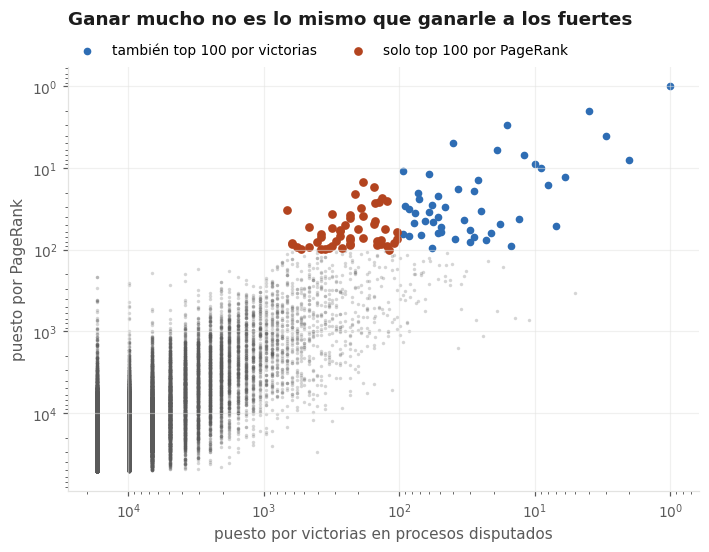

In [5]:
pr = pd.DataFrame({"nodo": idx3, "pagerank": pr3})
pr["rivales_vencidos"] = np.bincount(d3, minlength=len(idx3))
pr = pr.merge(ganadas, on="nodo", how="left").fillna({"victorias_disputadas": 0})
pr = (pr.merge(mapa, on="nodo", how="left")
        .merge(nodos_g1[["nodo", "participaciones", "n_ganados", "monto_total"]], on="nodo", how="left")
        .merge(clusters[["nodo", "cluster"]].merge(perfiles, on="cluster"), on="nodo", how="left"))
pr["perfil"] = pr.perfil.fillna("sin perfil, menos de 3 adjudicaciones")
pr["puesto_pagerank"] = pr.pagerank.rank(ascending=False, method="min").astype(int)
pr["puesto_victorias"] = pr.victorias_disputadas.rank(ascending=False, method="min").astype(int)
pr["pr_relativo"] = pr.pagerank * len(pr)          # 1 es el promedio
rho_v = stats.spearmanr(pr.pagerank, pr.victorias_disputadas).statistic
top100_pr = set(pr.nsmallest(100, "puesto_pagerank").nodo)
top100_v = set(pr.nsmallest(100, "puesto_victorias").nodo)
nuevos_top = len(top100_pr - top100_v)
print(f"Spearman entre PageRank y victorias: {rho_v:.3f}; "
      f"{nuevos_top} del top 100 de PageRank no están en el top 100 por victorias")
cols = ["puesto_pagerank", "puesto_victorias", "nombre", "tipo", "participaciones", "victorias_disputadas",
        "rivales_vencidos", "pr_relativo", "perfil"]
tabla_top = pr.nsmallest(25, "puesto_pagerank")[cols]
print(tabla_top.to_string(index=False))
suben = pr[(pr.puesto_pagerank <= 100)].assign(salto=lambda d: d.puesto_victorias - d.puesto_pagerank)
suben = suben.nlargest(10, "salto")[cols + ["salto"]]
print("\nLos que más suben al pasar de victorias a PageRank:")
print(suben.to_string(index=False))
exportar(pr.nsmallest(300, "puesto_pagerank")[cols + ["pagerank", "monto_total"]],
         "p4_pagerank_top", "Los 300 proveedores de mayor PageRank en el grafo de perdedor a ganador")

fig, ax = plt.subplots(figsize=(7.4, 5))
sub = pr[pr.victorias_disputadas > 0]
ax.scatter(sub.puesto_victorias, sub.puesto_pagerank, s=5, alpha=.25, color=SUAVE, linewidths=0)
top = pr.nsmallest(100, "puesto_pagerank")
nuevo = top.nodo.isin(top100_pr - top100_v)
ax.scatter(top.puesto_victorias[~nuevo], top.puesto_pagerank[~nuevo], s=16, color=AZUL, label="también top 100 por victorias")
ax.scatter(top.puesto_victorias[nuevo], top.puesto_pagerank[nuevo], s=22, color=ROJO, label="solo top 100 por PageRank")
ax.set_xscale("log"); ax.set_yscale("log"); ax.invert_xaxis(); ax.invert_yaxis()
ax.set_xlabel("puesto por victorias en procesos disputados"); ax.set_ylabel("puesto por PageRank")
ax.set_title("Ganar mucho no es lo mismo que ganarle a los fuertes", loc="left", pad=28)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.01), ncols=2, borderaxespad=0); ax.grid(alpha=.5)
s0 = suben.iloc[0]
figura(fig, "f21_pagerank_vs_victorias", f"""
Los dos rankings se parecen en el grueso (correlación de rangos de {rho_v:.2f}), pero no arriba: {nuevos_top}
de los 100 primeros por PageRank no están entre los 100 con más victorias en procesos disputados. Son los
puntos rojos, que quedan a la derecha porque ganan relativamente poco y aun así concentran rango, porque sus
victorias son contra proveedores que a su vez ganan. El caso más claro es {s0.nombre}, puesto
{s0.puesto_victorias} por victorias disputadas ({s0.victorias_disputadas:.0f}) y {s0.puesto_pagerank} por PageRank. Para quien supervisa competencia, este ranking
identifica a quien domina a sus competidores, que es una pregunta distinta de quién gana más veces.""")

## 5. Sensibilidad al factor de amortiguamiento

Beta es la probabilidad de seguir una arista en lugar de saltar al azar. Con beta bajo, el rango de un nodo depende sobre todo de sus votos directos; con beta alto, de cadenas largas de victorias, y el teletransporte casi no corrige trampas ni ciclos. La lecture usa 0,85 por convención. Aquí se barre de 0,50 a 0,99 y se mide cuánto cambia el top 100 respecto de 0,85 y cuántas iteraciones cuesta, porque el error decrece como beta elevado a t.

 beta  iteraciones  segundos  top100_comun_pct  top20_comun_pct  spearman
 0.50           26     0.063              76.0             75.0     0.997
 0.60           35     0.084              81.0             80.0     0.998
 0.70           50     0.120              86.0             90.0     0.999
 0.75           61     0.146              90.0             90.0     1.000
 0.80           79     0.189              96.0             95.0     1.000
 0.85          108     0.251             100.0            100.0     1.000
 0.90          165     0.392              93.0            100.0     1.000
 0.95          336     0.792              76.0             95.0     0.999
 0.99         1663     4.044              31.0             15.0     0.998



Lectura de f22_sensibilidad_beta
Entre beta 0,75 y 0,90 el top 100 conserva al menos el 90 por ciento de sus integrantes: el ranking es robusto en la zona razonable. En los extremos cambia: con 0,50 comparte el 76 por ciento, porque pesan casi solo los votos directos, y con 0,99 el 31 por ciento, porque el rango queda atrapado en cadenas largas de ganadores. El costo crece como predice la teoría, de 26 a 1663 iteraciones. Se mantiene 0,85: está en la meseta estable y converge en 108 pasos.



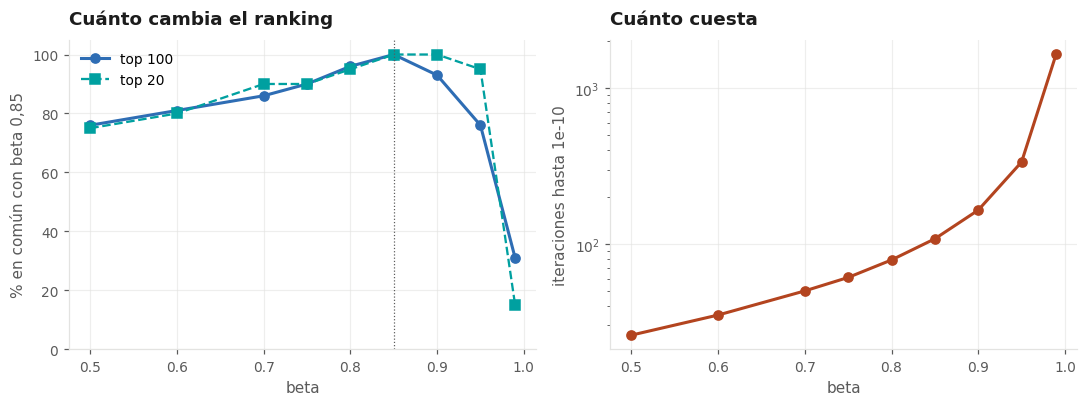

In [6]:
BETAS = [0.5, 0.6, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 0.99]
filas, rangos = [], {}
for b in BETAS:
    t0 = time.perf_counter()
    rb, itb = pagerank_local(M3, sin3, beta=b, tol=1e-10, max_iter=3000)
    rangos[b] = rb
    filas.append({"beta": b, "iteraciones": itb, "segundos": time.perf_counter() - t0,
                  "top100_comun_pct": 100 * solapamiento_top(rb, pr3, 100),
                  "top20_comun_pct": 100 * solapamiento_top(rb, pr3, 20),
                  "spearman": stats.spearmanr(rb, pr3).statistic})
sens = pd.DataFrame(filas)
print(sens.round(3).to_string(index=False))
exportar(sens, "p4_sensibilidad_beta", "Estabilidad del top 100 de PageRank y costo segun beta")
# Puesto de los 300 primeros en cada beta, para el control interactivo del reporte.
top300 = pr.nsmallest(300, "puesto_pagerank").nodo.values
pos = idx3.get_indexer(top300)
puestos = pd.DataFrame({"nodo": top300})
for b in BETAS:
    orden = np.empty(len(idx3), dtype=int); orden[np.argsort(-rangos[b])] = np.arange(1, len(idx3) + 1)
    puestos[f"b{b}"] = orden[pos]
exportar(puestos.merge(mapa, on="nodo", how="left").drop(columns="nodo"), "p4_puestos_beta", "Puesto de los 300 primeros segun beta")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.8))
a1.plot(sens.beta, sens.top100_comun_pct, "o-", color=AZUL, lw=2, label="top 100")
a1.plot(sens.beta, sens.top20_comun_pct, "s--", color=TEAL, lw=1.5, label="top 20")
a1.axvline(BETA, color=SUAVE, lw=.8, ls=":")
a1.set_xlabel("beta"); a1.set_ylabel("% en común con beta 0,85"); a1.set_ylim(0, 105)
a1.set_title("Cuánto cambia el ranking", loc="left", pad=10); a1.legend(); a1.grid(alpha=.6)
a2.plot(sens.beta, sens.iteraciones, "o-", color=ROJO, lw=2)
a2.set_yscale("log"); a2.set_xlabel("beta"); a2.set_ylabel("iteraciones hasta 1e-10")
a2.set_title("Cuánto cuesta", loc="left", pad=10); a2.grid(alpha=.6)
fig.tight_layout()
sb = sens.set_index("beta")
figura(fig, "f22_sensibilidad_beta", f"""
Entre beta 0,75 y 0,90 el top 100 conserva al menos el {min(sb.loc[0.75,'top100_comun_pct'], sb.loc[0.9,'top100_comun_pct']):.0f}
por ciento de sus integrantes: el ranking es robusto en la zona razonable. En los extremos cambia: con 0,50
comparte el {sb.loc[0.5,'top100_comun_pct']:.0f} por ciento, porque pesan casi solo los votos directos, y con
0,99 el {sb.loc[0.99,'top100_comun_pct']:.0f} por ciento, porque el rango queda atrapado en cadenas largas de
ganadores. El costo crece como predice la teoría, de {sb.loc[0.5,'iteraciones']:.0f} a {sb.loc[0.99,'iteraciones']:.0f}
iteraciones. Se mantiene 0,85: está en la meseta estable y converge en {sb.loc[0.85,'iteraciones']:.0f} pasos.""")

## 6. PageRank y los perfiles de la Parte II

Los perfiles de la Parte II se construyeron con rasgos de cada proveedor por separado. PageRank mira la posición en la red de competencia. Cruzarlos dice si el perfil cautivo, que gana sin rivales, tiene o no peso en la competencia abierta.

                               perfil  proveedores  percentil_mediano  en_top_1pct
sin perfil, menos de 3 adjudicaciones       123789               30.8          0.0
              cautivo sin competencia          320               65.9          0.3
                  contratista de obra         1042               92.9          2.5
                   competitivo típico         7622               93.4          3.9
            gran proveedor recurrente         2112               98.9         46.6



Lectura de f23_pagerank_perfil
De los 1,260 proveedores cautivos de la Parte II, solo 320 aparecen en algún proceso disputado; el resto nunca compitió contra nadie. Los que aparecen quedan en el percentil 66 de PageRank en la mediana, frente al 99 del gran proveedor recurrente. El cautivo gana sin rivales, así que casi nadie pierde contra él y no recibe votos. Su poder es de dependencia con una entidad, no de dominio en la competencia abierta. Las dos medidas miran dimensiones distintas del mercado y una supervisión completa necesita las dos.



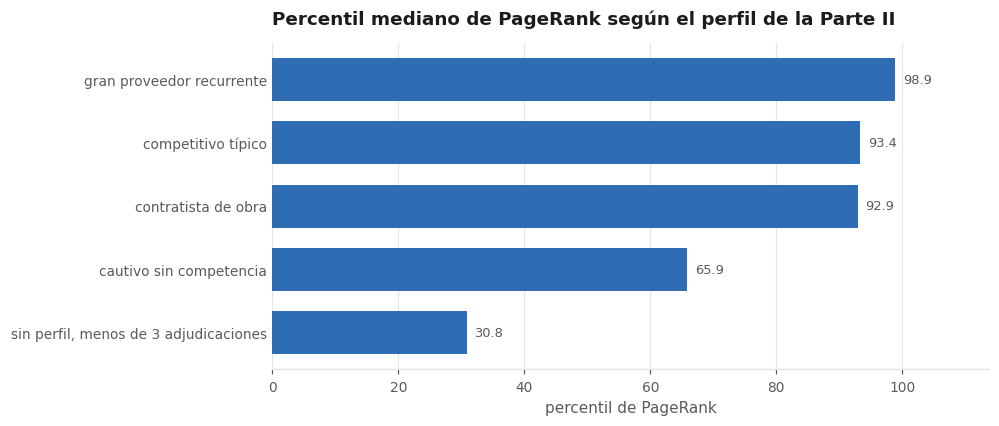

In [7]:
pr["percentil"] = 100 * pr.pagerank.rank(pct=True)
n_cautivos = (clusters.merge(perfiles, on="cluster").perfil.str.startswith("cautivo")).sum()
por_perfil = (pr.groupby("perfil")
                .agg(proveedores=("nodo", "size"), percentil_mediano=("percentil", "median"),
                     en_top_1pct=("percentil", lambda s: 100 * (s >= 99).mean()))
                .reset_index().sort_values("percentil_mediano"))
print(por_perfil.round(1).to_string(index=False))
exportar(por_perfil, "p4_pagerank_perfil", "Percentil de PageRank segun el perfil de la Parte II")
fig, ax = barras_h(por_perfil, "perfil", "percentil_mediano",
                   "Percentil mediano de PageRank según el perfil de la Parte II", "percentil de PageRank",
                   color=AZUL, alto=.55)
pp = por_perfil.set_index("perfil")
cautivo = [p for p in pp.index if p.startswith("cautivo")][0]
grande = [p for p in pp.index if p.startswith("gran")][0]
en_g3 = int(pp.loc[cautivo, "proveedores"])
figura(fig, "f23_pagerank_perfil", f"""
De los {n_cautivos:,} proveedores cautivos de la Parte II, solo {en_g3:,} aparecen en algún proceso disputado; el
resto nunca compitió contra nadie. Los que aparecen quedan en el percentil {pp.loc[cautivo,'percentil_mediano']:.0f}
de PageRank en la mediana, frente al {pp.loc[grande,'percentil_mediano']:.0f} del gran proveedor recurrente. El
cautivo gana sin rivales, así que casi nadie pierde contra él y no recibe votos. Su poder es
de dependencia con una entidad, no de dominio en la competencia abierta. Las dos medidas miran dimensiones
distintas del mercado y una supervisión completa necesita las dos.""")

## 7. HITS sobre el bipartito entidad a proveedor

**Por qué HITS aquí.** El bipartito tiene dos tipos de nodo con papeles distintos, y HITS da dos puntajes con papeles distintos. Un **hub** es una entidad que contrata a proveedores de referencia; una **authority** es un proveedor contratado por entidades que son buenos hubs. La definición es circular a propósito, y la iteración a = A transpuesta h, h = A a la resuelve.

**La matriz.** A tiene una fila por entidad y una columna por proveedor, con log(1 + adjudicaciones) de 2023 a 2025, la misma señal de la Parte III. Con el monto, una sola obra grande dominaría el vector.

**Lo que dice la teoría.** HITS converge al primer vector singular de A: los hubs son el vector singular izquierdo y las authorities el derecho. Se comprueba contra la descomposición en valores singulares de scipy.

In [8]:
ep = spark.read.parquet(str(BASE / "interaccion_entidad_proveedor")).groupBy("comprador_id", "clave") \
    .agg(F.sum("n").alias("n"), F.sum("monto").alias("monto")).toPandas()
nombres_p = (spark.read.parquet(str(BASE / "mapa_proveedores")).select("clave", "nombre", "tipo")
             .dropDuplicates(["clave"]).toPandas())
filas_e = pd.Index(sorted(ep.comprador_id.unique())); cols_p = pd.Index(sorted(ep.clave.unique()))
A = sparse.csr_matrix((np.log1p(ep.n.values), (filas_e.get_indexer(ep.comprador_id), cols_p.get_indexer(ep.clave))),
                      shape=(len(filas_e), len(cols_p)))
with cronometro("HITS por iteración de potencia"):
    hub, auth, it_h = hits_local(A)
U, sv, Vt = svds(A, k=8)
orden_sv = np.argsort(-sv); U, sv, Vt = U[:, orden_sv], sv[orden_sv], Vt[orden_sv]
corr_sv = abs(np.corrcoef(auth, Vt[0])[0, 1])
print(f"HITS en {it_h} iteraciones; correlación con el primer vector singular derecho: {corr_sv:.6f}")

hechos_pd = hechos.select("clave", "comprador_id", "familia", "departamento", "monto").toPandas()
def moda(df, clave, col):
    c = df.dropna(subset=[col]).groupby([clave, col]).size().reset_index(name="c")
    return c.sort_values("c").drop_duplicates(clave, keep="last").set_index(clave)[col]
fam_p, dep_p = moda(hechos_pd, "clave", "familia"), moda(hechos_pd, "clave", "departamento")

au = pd.DataFrame({"clave": cols_p, "authority": auth, "clientes": np.asarray((A > 0).sum(0)).ravel()})
au = au.merge(nombres_p, on="clave", how="left")
au["familia"], au["departamento"] = au.clave.map(fam_p), au.clave.map(dep_p)
au["monto"] = au.clave.map(hechos_pd.groupby("clave").monto.sum())
hb = pd.DataFrame({"comprador_id": filas_e, "hub": hub}).merge(
    entidades[["comprador_id", "comprador_nombre", "departamento", "nivel_gobierno", "n_proveedores", "monto_total"]],
    on="comprador_id", how="left")
masa_hub = np.sort(hub ** 2)[::-1]; masa_auth = np.sort(auth ** 2)[::-1]
rho_monto = stats.spearmanr(au.authority, au.monto.fillna(0)).statistic
rho_clientes = stats.spearmanr(au.authority, au.clientes).statistic
print(f"El primer hub concentra el {100*masa_hub[0]:.0f} % de la masa de hubs; los 20 primeros proveedores, "
      f"el {100*masa_auth[:20].sum():.0f} % de la masa de authorities")
print(f"Spearman de la authority con el monto: {rho_monto:.2f}; con el número de clientes: {rho_clientes:.2f}")
top_hubs = hb.nlargest(15, "hub"); top_auth = au.nlargest(15, "authority")
print(top_hubs[["comprador_nombre", "departamento", "nivel_gobierno", "n_proveedores", "hub"]].to_string(index=False))
print(top_auth[["nombre", "familia", "departamento", "clientes", "monto", "authority"]].to_string(index=False))
exportar(hb.nlargest(40, "hub"), "p4_hits_hubs", "Las 40 entidades con mayor puntaje de hub")
exportar(au.nlargest(40, "authority"), "p4_hits_authorities", "Los 40 proveedores con mayor puntaje de authority")

HITS por iteración de potencia: 0.04 s
HITS en 76 iteraciones; correlación con el primer vector singular derecho: 1.000000


El primer hub concentra el 64 % de la masa de hubs; los 20 primeros proveedores, el 24 % de la masa de authorities
Spearman de la authority con el monto: 0.11; con el número de clientes: 0.39
                                                   comprador_nombre departamento               nivel_gobierno  n_proveedores      hub
                                             SEGURO SOCIAL DE SALUD         LIMA                         Otro         1468.0 0.799091
CENTRO NACIONAL DE ABASTECIMIENTO DE RECURSOS ESTRATEGICOS EN SALUD         LIMA            Gobierno nacional          249.0 0.255218
                                     DIRECCIÓN DE SANIDAD DE LA PNP         LIMA                         Otro          228.0 0.151595
                                                   EJERCITO PERUANO         LIMA Fuerzas armadas y policiales          924.0 0.132763
                              IAFAS DEL EJERCITO DEL PERU (FOSPEME)         LIMA Fuerzas armadas y policiales          173.0 0.130390
    

,clave,authority,clientes,nombre,tipo,familia,departamento,monto
43937,RUC-20501887286,0.194633,105,DIAGNOSTICA PERUANA S.A.C.,empresa,4111,LIMA,2.773275e+08
40398,RUC-20347268683,0.129301,47,LABORATORIOS AC FARMA S.A.,empresa,5114,LIMA,2.038152e+08
40527,RUC-20377339461,0.126781,50,B.BRAUN MEDICAL PERU S.A.,empresa,5119,LIMA,1.470817e+08
40354,RUC-20338570041,0.123503,48,LINDE PERU S.R.L.,empresa,1214,LIMA,5.698266e+07
39844,RUC-20155695901,0.117577,46,SISTEMAS ANALITICOS SRL,empresa,4111,LIMA,9.594334e+07
39547,RUC-20108629909,0.109075,27,CARDIO PERFUSION E.I.R.LTDA,empresa,4229,LIMA,9.483944e+07
40099,RUC-20263368992,0.103122,33,CYMED MEDICAL SAC,empresa,8516,LIMA,9.390264e+07
39262,RUC-20100061474,0.100455,27,REPRESENTACIONES DECO S.A.C,empresa,5118,LIMA,5.800257e+07
39333,RUC-20100287791,0.099684,30,INSTITUTO QUIMIOTERAPICO S A,empresa,5113,LIMA,2.633678e+08
44017,RUC-20503794692,0.098206,33,NORDIC PHARMACEUTICAL COMPANY S.A.C,empresa,5113,LIMA,4.916809e+07



Lectura de f24_hits_hubs_authorities
HITS encuentra un núcleo y es el mercado de salud. SEGURO SOCIAL DE SALUD concentra el 64 por ciento de la masa de hubs, y lo siguen otros compradores de salud y de las fuerzas armadas. Las authorities son proveedores de diagnóstico, fármacos y equipo médico, encabezados por DIAGNOSTICA PERUANA S.A.C.; 15 de los 20 primeros operan en LIMA. Ser authority no es facturar más: la correlación con el monto es de 0.11. Es ser el proveedor al que acuden los compradores que más proveedores de referencia contratan. Este es el efecto que la lecture llama comunidad densa dominante: el primer vector se queda con el bloque mejor conectado de la matriz y no mira el resto.



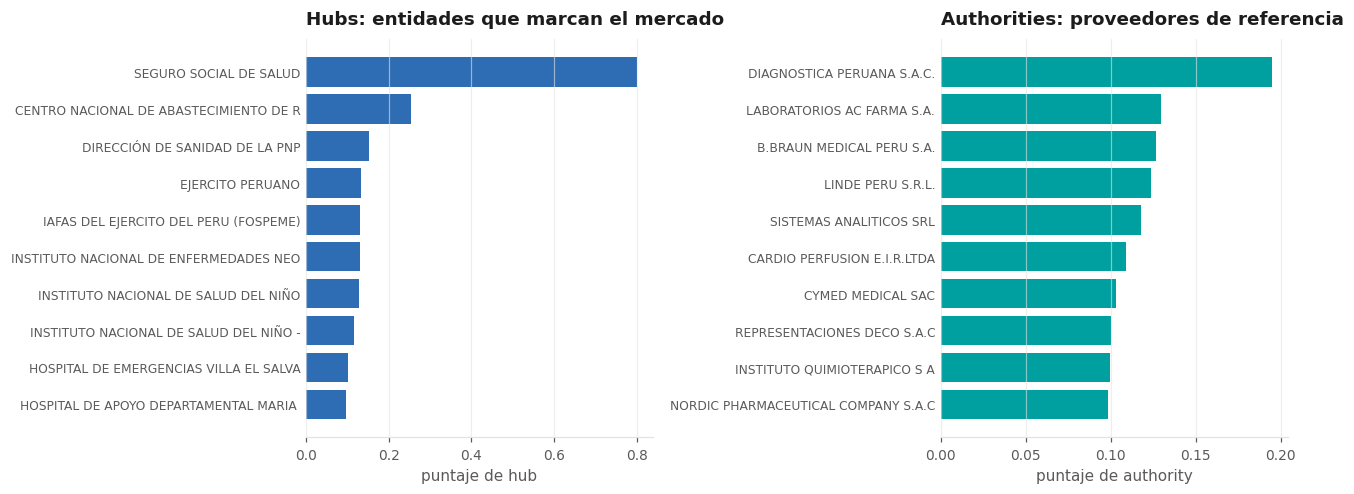

In [9]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.6))
h10, a10 = top_hubs.head(10).iloc[::-1], top_auth.head(10).iloc[::-1]
a1.barh([n[:38] for n in h10.comprador_nombre], h10.hub, color=AZUL)
a1.set_title("Hubs: entidades que marcan el mercado", loc="left", pad=10); a1.set_xlabel("puntaje de hub")
a2.barh([str(n)[:38] for n in a10.nombre], a10.authority, color=TEAL)
a2.set_title("Authorities: proveedores de referencia", loc="left", pad=10); a2.set_xlabel("puntaje de authority")
for a in (a1, a2):
    a.tick_params(axis="y", labelsize=8, length=0); a.grid(axis="x", alpha=.6); a.spines["left"].set_visible(False)
fig.tight_layout()
h0, a0 = top_hubs.iloc[0], top_auth.iloc[0]
deps = top_auth.head(20).departamento.value_counts()
figura(fig, "f24_hits_hubs_authorities", f"""
HITS encuentra un núcleo y es el mercado de salud. {h0.comprador_nombre} concentra el {100*masa_hub[0]:.0f} por ciento
de la masa de hubs, y lo siguen otros compradores de salud y de las fuerzas armadas. Las authorities son
proveedores de diagnóstico, fármacos y equipo médico, encabezados por {a0.nombre}; {deps.iloc[0]} de los 20
primeros operan en {deps.index[0]}. Ser authority no es facturar más: la correlación con el monto es de
{rho_monto:.2f}. Es ser el proveedor al que acuden los compradores que más proveedores de referencia
contratan. Este es el efecto que la lecture llama comunidad densa dominante: el primer vector se queda con el
bloque mejor conectado de la matriz y no mira el resto.""")

## 8. Más allá del primer vector: un mapa de mercados

Si HITS es el primer vector singular de A, los vectores siguientes son otros núcleos densos, ortogonales al primero. Leer cada uno por la familia CUBSO y el departamento dominantes de sus proveedores convierte la descomposición en un mapa de mercados, sin haberle dicho al algoritmo qué es un mercado. Es el puente con las Partes V y VI: las comunidades y los embeddings deberían reencontrar estos bloques.

El nombre de cada familia se toma del propio dato: la descripción CUBSO más frecuente de sus ítems adjudicados, leída en Spark desde los CSV crudos.

 vector  valor_singular familia                                                  item_tipico  pct_familia departamento  pct_departamento departamento_entidades
      1            50.8    4111 HEMOGRAMA AUTOMATIZADO DIFERENCIAL 5 ESTIRPES y 25 PARAMETRO           23         LIMA               100                   LIMA
      2            44.2    8010  SERVICIO DE SEGUIMIENTO Y MONITOREO DE ACTIVIDADES DE CAMPO           97         LIMA               100                   LIMA
      3            40.5    3011               CEMENTO PORTLAND PUZOLANICO TIPO IP X 42.50 kg           43        CUSCO                53                  CUSCO
      4            38.4    5013                       LECHE EVAPORADA ENTERA X 400 g  APROX.           13         LIMA                97                   LIMA
      5            31.1    3011               CEMENTO PORTLAND PUZOLANICO TIPO IP X 42.50 kg           30         PUNO                77                   PUNO
      6            30.3    8210         

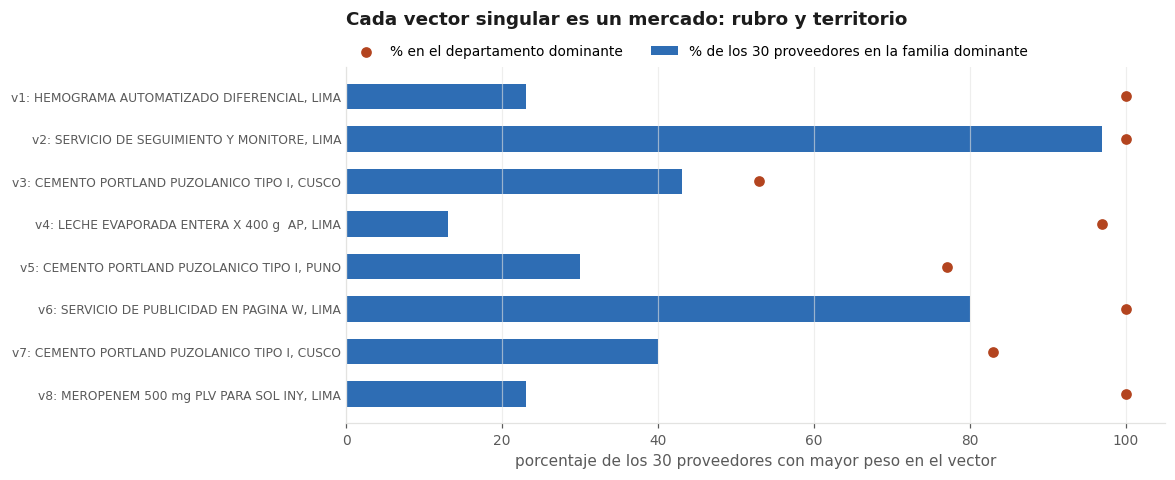

In [10]:
items = ingesta.leer(spark, "awards_items.csv", ["classification_id", "classification_description"])
nombre_familia = (items.dropna().withColumn("familia", F.substring("classification_id", 1, 4))
                  .groupBy("familia", "classification_description").count()
                  .withColumn("r", F.row_number().over(
                      __import__("pyspark.sql.window", fromlist=["Window"]).Window
                      .partitionBy("familia").orderBy(F.desc("count"))))
                  .filter("r = 1").select("familia", F.col("classification_description").alias("item_tipico"))
                  .toPandas().set_index("familia").item_tipico)

mercados = []
for j in range(len(sv)):
    v, u = Vt[j], U[:, j]
    signo = 1 if v[np.argmax(np.abs(v))] > 0 else -1      # el signo de un vector singular es arbitrario
    v, u = signo * v, signo * u
    tp, te_ = np.argsort(-v)[:30], np.argsort(-u)[:15]
    fams = au.familia.values[tp]; fam_top = pd.Series(fams).value_counts()
    dep_top = pd.Series(au.departamento.values[tp]).value_counts()
    ent_dep = hb.set_index("comprador_id").reindex(filas_e[te_]).departamento.value_counts()
    mercados.append({
        "vector": j + 1, "valor_singular": round(float(sv[j]), 1),
        "familia": fam_top.index[0], "item_tipico": str(nombre_familia.get(fam_top.index[0], ""))[:60],
        "pct_familia": round(100 * fam_top.iloc[0] / 30), "departamento": dep_top.index[0],
        "pct_departamento": round(100 * dep_top.iloc[0] / 30), "departamento_entidades": ent_dep.index[0],
        "proveedores": " | ".join(str(x)[:40] for x in au.nombre.values[tp[:4]]),
        "entidades": " | ".join(str(x)[:40] for x in hb.set_index("comprador_id").reindex(filas_e[te_[:3]]).comprador_nombre)})
mercados = pd.DataFrame(mercados)
print(mercados.drop(columns=["proveedores", "entidades"]).to_string(index=False))
exportar(mercados, "p4_mercados_svd", "Mercado que representa cada uno de los ocho primeros vectores singulares")

fig, ax = plt.subplots(figsize=(9.6, 4.2))
y = np.arange(len(mercados))[::-1]
ax.barh(y, mercados.pct_familia, color=AZUL, height=.6, label="% de los 30 proveedores en la familia dominante")
ax.scatter(mercados.pct_departamento, y, color=ROJO, zorder=3, label="% en el departamento dominante")
ax.set_yticks(y, [f"v{r.vector}: {r.item_tipico[:34]}, {r.departamento}" for r in mercados.itertuples()], fontsize=8)
ax.set_xlim(0, 105); ax.set_xlabel("porcentaje de los 30 proveedores con mayor peso en el vector")
ax.set_title("Cada vector singular es un mercado: rubro y territorio", loc="left", pad=28)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.01), ncols=2, borderaxespad=0); ax.grid(axis="x", alpha=.6)
ax.tick_params(axis="y", length=0)
mf = mercados.set_index("vector")
figura(fig, "f25_mercados_svd", f"""
Cada vector singular agrupa proveedores de un mismo rubro o de un mismo territorio. El primero, que es
HITS, es salud en Lima. El segundo reúne a proveedores de la familia {mf.loc[2,'familia']}, cuyo ítem típico es
{mf.loc[2,'item_tipico'].lower()}, y el {mf.loc[2,'pct_departamento']:.0f} por ciento opera en {mf.loc[2,'departamento']}.
Otros vectores son territoriales, con proveedores de {mf.loc[3,'departamento']} o de {mf.loc[5,'departamento']}
dominando su vector. El cuarto tiene como ítem típico {mf.loc[4,'item_tipico'].lower()}: son los programas
alimentarios, la misma huella que dejó la canasta de las reglas de asociación del proyecto 1. Para un supervisor es un índice de mercados construido sin etiquetas: cada vector
dice qué entidades y qué proveedores forman un bloque, y la Parte V verifica si las comunidades del
grafo reencuentran esos mismos bloques.""")

## 9. Los pares afines: quién gana cuando se presentan juntos

La Parte I dejó una cola de revisión: pares de proveedores con al menos 10 procesos compartidos que coinciden en el 80 por ciento o más de las participaciones del menos activo. La afinidad dice que se presentan juntos, no qué pasa cuando lo hacen. El grafo de perdedor a ganador lo dice, y separa tres situaciones con lecturas de negocio distintas:

1. **Pierden juntos.** En casi todos sus procesos compartidos gana un tercero o nadie. Es el patrón de quien se registra en masa como participante; en el SEACE registrarse no es presentar oferta.
2. **Siempre gana el mismo.** Cuando uno de los dos gana, es siempre el mismo. Puede ser un competidor más fuerte o un acompañante que nunca gana.
3. **Alternan.** Cada uno le gana al otro en una fracción apreciable de los procesos que se deciden entre ellos. Es el patrón que la literatura de competencia llama rotación de ganadores, y también el de dos empresas que se reparten un mercado pequeño de forma legítima.

Para saber si estos patrones son propios de los pares afines se comparan con un grupo de control: 5.000 pares con al menos 10 procesos compartidos y afinidad menor a 0,3.

In [11]:
ar = spark.read.parquet(str(BASE / "grafo_aristas")).filter("procesos >= 10").toPandas()
p_n = nodos_g1.set_index("nodo").participaciones
ar["afinidad"] = ar.procesos / np.minimum(ar.src.map(p_n), ar.dst.map(p_n))
afines = ar[ar.afinidad >= 0.8]
control = ar[ar.afinidad < 0.3].sample(5000, random_state=0)
print(f"pares afines: {len(afines):,}; pares de control: {len(control):,}")

part_pd = part.toPandas()
gan_pd = gan.select("ocid", "nodo").toPandas().assign(g=1)
con_ganador = set(gan_pd.ocid)

def patron(pares):
    """Para cada par, en sus procesos compartidos: cuántas veces ganó cada uno, ambos, un tercero o nadie."""
    ns = np.union1d(pares.src, pares.dst)
    p = part_pd[part_pd.nodo.isin(ns)].merge(gan_pd, on=["ocid", "nodo"], how="left").fillna({"g": 0})
    x = (pares[["src", "dst"]].merge(p.rename(columns={"nodo": "src", "g": "gs"}), on="src")
         .merge(p.rename(columns={"nodo": "dst", "g": "gd"}), on=["dst", "ocid"]))
    x["res"] = np.select([(x.gs == 1) & (x.gd == 0), (x.gs == 0) & (x.gd == 1), (x.gs == 1) & (x.gd == 1),
                          x.ocid.isin(con_ganador)], ["gana_a", "gana_b", "ambos", "tercero"], "nadie")
    t = x.groupby(["src", "dst"]).res.value_counts().unstack(fill_value=0)
    for c in ["gana_a", "gana_b", "ambos", "tercero", "nadie"]:
        if c not in t: t[c] = 0
    t["compartidos"] = t[["gana_a", "gana_b", "ambos", "tercero", "nadie"]].sum(1)
    t["entre_ellos"] = t.gana_a + t.gana_b
    t["alternancia"] = np.where(t.entre_ellos > 0, np.minimum(t.gana_a, t.gana_b) / t.entre_ellos, np.nan)
    t["patron"] = np.select([t.entre_ellos + t.ambos < 0.05 * t.compartidos, t.alternancia >= 0.25],
                            ["pierden juntos", "alternan"], "siempre gana el mismo")
    return t.reset_index()

pa_, pc_ = patron(afines), patron(control)
resumen = pd.concat([pa_.patron.value_counts(normalize=True).rename("afines"),
                     pc_.patron.value_counts(normalize=True).rename("control")], axis=1).fillna(0) * 100
resumen = resumen.reindex(["pierden juntos", "siempre gana el mismo", "alternan"]).round(1)
print(resumen)
exportar(resumen.reset_index(names="patron"), "p4_patrones_pares", "Patron de victorias en pares afines frente al control")
pa_ = pa_.merge(afines[["src", "dst", "afinidad"]], on=["src", "dst"])
pa_ = (pa_.merge(mapa.rename(columns={"nodo": "src", "nombre": "proveedor_a", "tipo": "tipo_a"}), on="src", how="left")
          .merge(mapa.rename(columns={"nodo": "dst", "nombre": "proveedor_b", "tipo": "tipo_b"}), on="dst", how="left"))
# Insumos para la Parte V, con identificadores de nodo.
pa_[["src", "dst", "compartidos", "afinidad", "alternancia", "patron"]].to_parquet(CACHE / "pares_afines.parquet")
nombre_familia.rename("item_tipico").to_frame().to_parquet(CACHE / "nombre_familia.parquet")
exportar(pa_[pa_.patron == "alternan"].nlargest(15, "compartidos")[
    ["proveedor_a", "proveedor_b", "compartidos", "afinidad", "gana_a", "gana_b", "alternancia"]],
    "p4_pares_alternan_top", "Los 15 pares que alternan victorias con mas procesos compartidos")
_ = exportar(pa_.sort_values("compartidos", ascending=False)[
    ["proveedor_a", "proveedor_b", "compartidos", "afinidad", "gana_a", "gana_b", "ambos", "tercero", "nadie",
     "alternancia", "patron"]], "p4_pares_afines", "Pares afines con su patron de victorias")

pares afines: 4,847; pares de control: 5,000


                       afines  control
patron                                
pierden juntos           43.9     71.6
siempre gana el mismo    38.5     23.1
alternan                 17.6      5.4



Lectura de f26_patrones_pares
El 44 por ciento de los pares afines pierde junto: se presentan a los mismos procesos y casi nunca gana ninguno, lo que encaja con el registro masivo de participantes y no con una competencia real entre ellos. La señal está en la barra roja: el 18 por ciento de los pares afines alterna victorias, frente al 5 por ciento del control. Son 851 pares que se presentan juntos casi siempre y se turnan para ganar. No prueba coordinación, porque dos proveedores pueden repartirse legítimamente un mercado chico, pero es la combinación que justifica pedir las ofertas completas de esos procesos y mirar precios y tiempos.



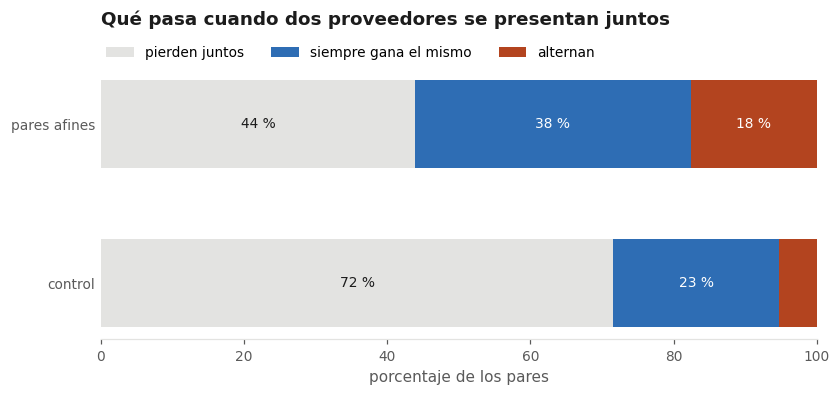

In [12]:
fig, ax = plt.subplots(figsize=(8.4, 3.2))
izq = np.zeros(2)
for color, pat in zip([REJILLA, AZUL, ROJO], resumen.index):
    vals = resumen.loc[pat, ["afines", "control"]].values
    ax.barh(["pares afines", "control"], vals, left=izq, color=color, label=pat, height=.55)
    for k, v in enumerate(vals):
        if v > 6: ax.text(izq[k] + v / 2, k, f"{v:.0f} %", ha="center", va="center", fontsize=9,
                          color=TINTA if color == REJILLA else "white")
    izq += vals
ax.set_xlim(0, 100); ax.set_xlabel("porcentaje de los pares"); ax.invert_yaxis()
ax.set_title("Qué pasa cuando dos proveedores se presentan juntos", loc="left", pad=28)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.01), ncols=3, borderaxespad=0)
ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)
r = resumen
alt_af = pa_[pa_.patron == "alternan"]
figura(fig, "f26_patrones_pares", f"""
El {r.loc['pierden juntos','afines']:.0f} por ciento de los pares afines pierde junto: se presentan a los mismos
procesos y casi nunca gana ninguno, lo que encaja con el registro masivo de participantes y no con una
competencia real entre ellos. La señal está en la barra roja: el {r.loc['alternan','afines']:.0f} por ciento de los
pares afines alterna victorias, frente al {r.loc['alternan','control']:.0f} por ciento del control. Son
{len(alt_af):,} pares que se presentan juntos casi siempre y se turnan para ganar. No prueba coordinación,
porque dos proveedores pueden repartirse legítimamente un mercado chico, pero es la combinación que justifica
pedir las ofertas completas de esos procesos y mirar precios y tiempos.""")

## 10. Hallazgos de la Parte IV

In [13]:
s0 = suben.iloc[0]
hallazgo("IV", "Ganar mucho no es lo mismo que dominar a quienes compiten",
         f"""En el grafo de perdedor a ganador, {nuevos_top} de los 100 proveedores de mayor PageRank no están entre
         los 100 con más victorias en procesos disputados. Suben porque le ganan a proveedores que a su vez ganan,
         como {s0.nombre}, puesto {s0.puesto_victorias} por victorias y {s0.puesto_pagerank} por PageRank. El ranking es
         estable entre beta 0,75 y 0,90, y de los {n_cautivos:,} proveedores cautivos de la Parte II solo {en_g3:,} compitieron alguna
         vez: su poder es la dependencia de una entidad, no el dominio de la competencia.""",
         """Usar el PageRank del grafo de perdedor a ganador como indicador de dominio en los tableros de
         competencia, al lado del conteo de victorias, y mirar con prioridad a quien sube mucho de un ranking al
         otro en rubros con pocos oferentes.""",
         "f21_pagerank_vs_victorias, f22_sensibilidad_beta, p4_pagerank_top")
hallazgo("IV", "El mercado de salud es el núcleo de la red y depende de pocos compradores",
         f"""HITS sobre el bipartito entidad a proveedor converge a un núcleo de salud en Lima.
         {h0.comprador_nombre} concentra el {100*masa_hub[0]:.0f} por ciento de la masa de hubs y las authorities son
         proveedores de diagnóstico, fármacos y equipo médico. Ser authority no es facturar más, correlación de
         {rho_monto:.2f} con el monto. Los vectores siguientes son otros mercados, por rubro y por territorio.""",
         """Empezar la supervisión de competencia en insumos médicos por los compradores con mayor puntaje de hub,
         porque sus decisiones de compra definen quién es proveedor de referencia para el resto, y usar los
         vectores singulares como índice de mercados para repartir la revisión.""",
         "f24_hits_hubs_authorities, f25_mercados_svd, p4_hits_hubs, p4_mercados_svd")
hallazgo("IV", "Entre los pares que se presentan juntos, la señal es la alternancia",
         f"""De los {len(pa_):,} pares afines de la Parte I, el {r.loc['pierden juntos','afines']:.0f} por ciento pierde junto
         y casi nunca gana, un patrón de registro masivo y no de competencia. El {r.loc['alternan','afines']:.0f} por ciento
         alterna victorias, frente al {r.loc['alternan','control']:.0f} por ciento de pares no afines con tantos procesos
         compartidos: {len(alt_af):,} pares se presentan juntos casi siempre y se turnan para ganar.""",
         """Reducir la cola de revisión de pares afines a los que alternan victorias, y para ellos pedir las
         ofertas completas de los procesos compartidos para comparar precios, como señal descriptiva y no como
         acusación.""",
         "f26_patrones_pares, p4_pares_afines")


HALLAZGO. Ganar mucho no es lo mismo que dominar a quienes compiten
En el grafo de perdedor a ganador, 51 de los 100 proveedores de mayor PageRank no están entre los 100 con más victorias en procesos disputados. Suben porque le ganan a proveedores que a su vez ganan, como CONSTRUCTORA GIRL POWER E.I.R.L., puesto 670 por victorias y 33 por PageRank. El ranking es estable entre beta 0,75 y 0,90, y de los 1,260 proveedores cautivos de la Parte II solo 320 compitieron alguna vez: su poder es la dependencia de una entidad, no el dominio de la competencia.
Accion propuesta: Usar el PageRank del grafo de perdedor a ganador como indicador de dominio en los tableros de competencia, al lado del conteo de victorias, y mirar con prioridad a quien sube mucho de un ranking al otro en rubros con pocos oferentes.


HALLAZGO. El mercado de salud es el núcleo de la red y depende de pocos compradores
HITS sobre el bipartito entidad a proveedor converge a un núcleo de salud en Lima. SEGURO SOCIAL DE SALU

In [14]:
# Subgrafo para el reporte: los 120 primeros por PageRank y las aristas entre ellos, para que el
# navegador recalcule PageRank en vivo al mover beta. Mas el resumen de la parte.
# Los identificadores de nodo son enteros de 64 bits y JavaScript los redondea al leer JSON, así que
# el subgrafo se exporta con índices posicionales 0 a 119.
sub = pr.nsmallest(120, "puesto_pagerank")[["nodo", "nombre", "tipo", "perfil", "victorias_disputadas", "puesto_pagerank"]]
sub = sub.reset_index(drop=True)
pos_sub = pd.Series(sub.index, index=sub.nodo)
ar_sub = G3[G3.src.isin(sub.nodo) & G3.dst.isin(sub.nodo)]
ar_sub = pd.DataFrame({"i": pos_sub[ar_sub.src].values, "j": pos_sub[ar_sub.dst].values,
                       "peso": ar_sub.peso.round(4).values, "procesos": ar_sub.procesos.values})
exportar(sub.drop(columns="nodo").reset_index(names="i"), "p4_subgrafo_nodos", "Los 120 primeros por PageRank, para recalcular en el navegador")
exportar(ar_sub, "p4_subgrafo_aristas", "Aristas de perdedor a ganador entre los 120 primeros, con indices posicionales")
exportar(pd.DataFrame([{"nodos_g3": len(idx3), "aristas_g3": len(G3), "spearman_g1": round(rho1, 3),
                        "top100_g1_pct": round(100 * top1), "spearman_victorias": round(rho_v, 3), "cautivos": int(n_cautivos), "cautivos_que_compiten": en_g3,
                        "nuevos_top100": nuevos_top, "iteraciones_spark": len(historial),
                        "segundos_spark": round(t_spark, 1), "segundos_local": round(t_local, 2),
                        "hub_principal": h0.comprador_nombre, "masa_hub_principal": round(100 * masa_hub[0], 1),
                        "rho_authority_monto": round(rho_monto, 2), "pares_afines": len(pa_),
                        "pares_alternan": len(alt_af)}]), "p4_resumen", "Cifras clave de la Parte IV")
exportar(pd.DataFrame(FIGURAS), "p4_figuras", "Figuras de la Parte IV con su lectura")
exportar(pd.DataFrame(HALLAZGOS), "p4_hallazgos", "Hallazgos de la Parte IV con su accion propuesta")

,parte,titulo,insight,accion,evidencia
0,IV,Ganar mucho no es lo mismo que dominar a quienes compiten,"En el grafo de perdedor a ganador, 51 de los 100 proveedores...",Usar el PageRank del grafo de perdedor a ganador como indica...,"f21_pagerank_vs_victorias, f22_sensibilidad_beta, p4_pageran..."
1,IV,El mercado de salud es el núcleo de la red y depende de poco...,HITS sobre el bipartito entidad a proveedor converge a un nú...,Empezar la supervisión de competencia en insumos médicos por...,"f24_hits_hubs_authorities, f25_mercados_svd, p4_hits_hubs, p..."
2,IV,"Entre los pares que se presentan juntos, la señal es la alte...","De los 4,847 pares afines de la Parte I, el 44 por ciento pi...",Reducir la cola de revisión de pares afines a los que altern...,"f26_patrones_pares, p4_pares_afines"


**Cierre.** La pregunta de esta parte era quién es central y qué significa serlo, y la respuesta tiene tres capas. En la competencia abierta, central es quien le gana a quienes ganan, y ese ranking no coincide con el de victorias en la cima. En la relación de compra, el centro es el mercado de salud de Lima, organizado alrededor de unos pocos compradores grandes, y los vectores siguientes dibujan un mapa de mercados por rubro y territorio. Y entre los pares que se presentan juntos, la mayoría no compite de verdad y una minoría alterna victorias, que es la que merece revisión.

**Decisiones que conviene recordar.** PageRank sobre el grafo no dirigido se descartó con una medición, no por intuición. El grafo dirigido excluye los procesos masivos y los desiertos. Beta igual a 0,85 está en la zona estable del barrido. Y HITS se interpreta como el primer vector singular, lo que explica por qué se queda con un solo mercado.

**Encuadre ético.** Ningún puntaje de esta parte es una acusación. Un PageRank alto puede ser eficiencia, una authority puede ser el único proveedor con registro sanitario de un insumo, y dos proveedores que alternan pueden ser los únicos de su provincia. Son criterios para ordenar una revisión con información que el analista no tiene, como las ofertas completas y los precios.

In [15]:
spark.stop()